# Reaction-network oracles: recovering kinetic timescales

`ReactionNetworkBenchmark` ships mass-action reaction datasets whose FAIR
cards carry **oracle** references: the equilibrium, the conservation laws,
and the Jacobian eigenvalues $\lambda$ that set the true kinetic
timescales $-1/\mathrm{Re}(\lambda)$. A discrete operator learned with
sample interval $\Delta t$ should match $e^{\lambda \Delta t}$.

This notebook checks three estimators against those oracles:
exact dynamic mode decomposition (DMD) on raw concentrations, DMD on the
card's log-concentration features, and a short `GraphKoopmanModel` fit
with `koopman="graph"`. It then uses `element_balance_violation` to test
whether decoded rollouts conserve mass.

**Honesty.** These are diagnostic / teaching datasets, not a production
kinetics benchmark. The oracle spectrum of a nonlinear system is its
**linearization** at one equilibrium, so it describes the late-time
approach, not the transient. The neural fit is a short CPU smoke run, not
a tuned model. This notebook does **not** download METR-LA and does not
need the `[cantera]` extra.

## Setup

Package version, seeds, and two cards: the linear chain
`reaction_chain_v1` (exact spectrum) and the nonlinear
`reaction_michaelis_menten_v1` (two conservation laws, boundary
equilibrium). `nearest_error` matches each oracle eigenvalue to the
closest estimated one.

In [1]:
from __future__ import annotations

import dataclasses
import math
import os
import warnings

from tqdm.std import TqdmWarning

warnings.filterwarnings("ignore", category=TqdmWarning)

import matplotlib

if os.environ.get("PYTEST_CURRENT_TEST"):
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import torch

import koopman_graph
from koopman_graph import GNNDecoder, GNNEncoder, GraphKoopmanModel
from koopman_graph.baselines import DMDBaseline
from koopman_graph.data import GraphSnapshotSequence, MultiTrajectory
from koopman_graph.datasets import ReactionNetworkBenchmark
from koopman_graph.datasets.reaction import (
    element_balance_violation,
    equilibrium,
    oracle_spectrum,
)
from koopman_graph.training import LossWeights

SEED = 0
_ = torch.manual_seed(SEED)
EPOCHS = 40  # CI smoke budget; the Results text describes this run

print("koopman_graph", koopman_graph.__version__)
print("cards", ReactionNetworkBenchmark.dataset_ids())


def nearest_error(estimated: torch.Tensor, oracle: torch.Tensor) -> list[float]:
    estimated = estimated.to(torch.complex128)
    return [float((estimated - target).abs().min()) for target in oracle]


def rollout_states(predictor, sequence: GraphSnapshotSequence) -> torch.Tensor:
    first = sequence[0]
    with torch.no_grad():
        predicted = predictor.predict(first, sequence.num_timesteps - 1)
    frames = [first.x] + [snapshot.x for snapshot in predicted]
    return torch.stack([frame.squeeze(-1).to(torch.float64) for frame in frames])

koopman_graph 0.15.0
cards ('reaction_brusselator_v1', 'reaction_cantera_h2o2_v1', 'reaction_chain_v1', 'reaction_michaelis_menten_v1', 'reaction_random_network_v1', 'reaction_van_de_vusse_v1')


## Motivation and background

Most graph-dynamics datasets only allow forecast-error comparisons.
Mass-action networks also come with exact structure: the stoichiometric
matrix $N$, conservation laws $W$ with $W N = 0$, and the Jacobian
$J = N\,\partial r/\partial c$ at equilibrium. For a closed system,
$J$ has one zero eigenvalue per conservation law. The remaining
eigenvalues are the relaxation rates a learned latent operator should
recover. Their discrete-time images $e^{\lambda \Delta t}$ are what a
Koopman matrix trained at sample interval $\Delta t$ can match, and a
conserved total maps to the eigenvalue $1$.

The cards store these oracles under `oracle`. `compute_card_oracle` and
`scripts/build_reaction_cards.py --check` keep them in sync with the
code.

## Minimal example

The chain $S_0 \to S_1 \to S_2 \to S_3$ (rates $1, 0.5, 0.25$) is
linear, so exact DMD on **raw** concentrations should recover
$\{1, e^{-0.25\Delta t}, e^{-0.5\Delta t}, e^{-\Delta t}\}$ from one
trajectory. The card's features are log-concentrations, so we switch the
transform off with `dataclasses.replace(..., transform=None)`.

In [2]:
chain_card = ReactionNetworkBenchmark.load_card("reaction_chain_v1")
dt = chain_card["time_step"]
oracle = chain_card["oracle"]
print("oracle state", oracle["state"])
print("dynamic eigenvalues", oracle["dynamic_eigenvalues_real"])
print("timescales", oracle["timescales"])
print("conservation laws", oracle["num_conservation_laws"])

chain_oracle = torch.tensor(
    [1.0] + [math.exp(r * dt) for r in oracle["dynamic_eigenvalues_real"]],
    dtype=torch.complex128,
)

chain = ReactionNetworkBenchmark.generate(
    "reaction_chain_v1", num_trajectories=8, num_timesteps=48
)
chain_raw = dataclasses.replace(chain, transform=None)
dmd = DMDBaseline(time_step=dt).fit(chain_raw.sequence(0))
dmd_eigenvalues = dmd.spectrum().eigenvalues
dmd_error = nearest_error(dmd_eigenvalues, chain_oracle)
print("oracle exp(lambda dt)", [round(abs(z), 6) for z in chain_oracle.tolist()])
print("DMD nearest errors", [f"{e:.1e}" for e in dmd_error])
assert max(dmd_error) < 1e-5

oracle state equilibrium_from_range_midpoints
dynamic eigenvalues [-0.25, -0.5, -1.0]
timescales [4.0, 2.0, 1.0]
conservation laws 1
oracle exp(lambda dt) [1.0, 0.939413, 0.882497, 0.778801]
DMD nearest errors ['0.0e+00', '6.7e-08', '6.9e-08', '5.7e-08']


## Progressive deep dive

**Feature transform.** The same DMD on the card's log-concentration
features no longer sees a linear system. `log` makes the chain
nonlinear, and the floor $10^{-8}$ saturates near-empty species, so the
eigenvalues move away from the oracle.

In [3]:
log_eigenvalues = DMDBaseline(time_step=dt).fit(chain.sequence(0)).spectrum().eigenvalues
log_error = nearest_error(log_eigenvalues, chain_oracle)
print("transform", chain.card["transform"])
print("DMD on log features, nearest errors", [round(e, 3) for e in log_error])
assert max(log_error) > 0.05

transform {'kind': 'log_concentration', 'floor': 1e-08}
DMD on log features, nearest errors [0.028, 0.082, 0.07, 0.134]


**Neural operator.** `koopman="graph"` couples species through the
influence graph (an edge $s \to t$ when $s$ is a reactant of a reaction
that changes $t$), so its spectrum is graph-level and needs `edge_index`.
The default `koopman="pernode"` applies one shared matrix to each node
and cannot represent the cross-species coupling that sets these modes.
The fit below uses raw concentrations, 8 trajectories, the CI epoch
budget, and `koopman_filter_degree=2` so the operator's mixing matches the
two-hop encoder (otherwise `ReceptiveFieldMismatchWarning`).

In [4]:
_ = torch.manual_seed(SEED)
latent_dim = 2
model = GraphKoopmanModel(
    encoder=GNNEncoder(1, 16, latent_dim),
    decoder=GNNDecoder(latent_dim, 16, 1),
    latent_dim=latent_dim,
    time_step=dt,
    koopman="graph",
    koopman_filter_degree=2,  # match the 2-hop GNNEncoder receptive field
)
train = MultiTrajectory([chain_raw.sequence(i) for i in range(chain_raw.num_trajectories)])
history = model.fit(
    train,
    epochs=EPOCHS,
    lr=3e-3,
    loss_weights=LossWeights(reconstruction=1.0, forward=1.0, rollout=1.0),
    rollout_horizon=8,
    rollout_start_seed=SEED,
)
model.eval()
graph = chain_raw.sequence(0)[0]
neural_spectrum = model.spectrum(
    edge_index=graph.edge_index,
    num_nodes=chain_raw.system.num_species,
    edge_weight=graph.edge_weight,
)
neural_eigenvalues = neural_spectrum.eigenvalues.detach()
neural_error = nearest_error(neural_eigenvalues, chain_oracle)
print(f"epochs {EPOCHS}, final loss {history.loss[-1]:.3e}")
print("effective operator eigenvalues", neural_eigenvalues.numel())
print("neural nearest errors", [round(e, 3) for e in neural_error])
assert neural_eigenvalues.numel() == latent_dim * chain_raw.system.num_species
assert all(math.isfinite(e) for e in neural_error)

epochs 40, final loss 1.445e-01
effective operator eigenvalues 8
neural nearest errors [0.004, 0.005, 0.051, 0.155]


**Conservation check.** The chain conserves total mass $\sum_s c_s$
(one element `M`). `element_balance_violation` returns the drift
$E\,(c_t - c_0)$ of a decoded rollout. DMD inherits conservation from
data that conserve it. A short neural fit does not, and the drift shows
that even where some eigenvalues look close.

In [5]:
held_out = chain_raw.sequence(1)
truth = chain.concentrations[1]
element_matrix = chain.system.element_matrix

dmd_states = rollout_states(dmd, held_out)
neural_states = rollout_states(model, held_out)
dmd_drift = element_balance_violation(dmd_states, dmd_states[0], element_matrix).abs().squeeze(-1)
neural_drift = element_balance_violation(neural_states, neural_states[0], element_matrix).abs().squeeze(-1)

print(f"DMD    max |drift| {float(dmd_drift.max()):.2e}, max |error| {float((dmd_states - truth).abs().max()):.2e}")
print(f"neural max |drift| {float(neural_drift.max()):.2e}, max |error| {float((neural_states - truth).abs().max()):.2e}")
assert float(dmd_drift.max()) < 1e-4
assert bool(torch.isfinite(neural_drift).all())

DMD    max |drift| 3.53e-06, max |error| 3.31e-06
neural max |drift| 5.83e-01, max |error| 1.03e+00


**Nonlinear card.** For Michaelis-Menten the card's oracle is the
linearization at the equilibrium reached from the **midpoint** of the
initial ranges. Each trajectory has its own conserved enzyme and substrate
totals, so its oracle must be recomputed with `equilibrium` and
`oracle_spectrum`. Near the boundary equilibrium ($S = ES = 0$) the
dynamics are close to linear, so DMD on a late window should recover the
slow mode. The fast mode has decayed below what the window can resolve;
DMD then reports a near-Nyquist alias for it (the `UserWarning` below),
which is a symptom of the unresolved mode, not of the slow one.

In [6]:
mm = ReactionNetworkBenchmark.generate(
    "reaction_michaelis_menten_v1", num_trajectories=2, num_timesteps=64
)
mm_raw = dataclasses.replace(mm, transform=None)
mm_dt = mm.card["time_step"]
c0 = mm.concentrations[0, 0]
own_equilibrium = equilibrium(mm.system, c0)
own_spectrum = oracle_spectrum(mm.system, own_equilibrium)
own_discrete = own_spectrum.discrete_eigenvalues(mm_dt)
card_discrete = [math.exp(r * mm_dt) for r in mm.card["oracle"]["dynamic_eigenvalues_real"]]
print("card oracle (range midpoint)  exp(lambda dt)", [round(x, 4) for x in card_discrete])
print("this trajectory's oracle      exp(lambda dt)", [round(abs(z), 4) for z in own_discrete.tolist()])
print("conservation laws", own_spectrum.num_conservation_laws)

full = mm_raw.sequence(0, graph_encoding="species_influence")  # DMD rejects hyperedges
window_starts = (0, 16, 32, 48)
slow_errors = []
for start in window_starts:
    window = GraphSnapshotSequence([full[i] for i in range(start, full.num_timesteps)])
    estimate = DMDBaseline(time_step=mm_dt).fit(window).spectrum().eigenvalues
    slow_errors.append(nearest_error(estimate, own_discrete[:1])[0])
print("slow-mode error by window start", dict(zip(window_starts, [round(e, 4) for e in slow_errors])))
assert slow_errors[-1] < 0.005
assert slow_errors[-1] < slow_errors[0]

card oracle (range midpoint)  exp(lambda dt) [0.8825, 0.2865]
this trajectory's oracle      exp(lambda dt) [0.864, 0.2337]
conservation laws 2
slow-mode error by window start {0: 0.0952, 16: 0.0961, 32: 0.0479, 48: 0.0007}


/Users/traviskessler/GitHub-Cursor/KoopmanGraph/.claude/worktrees/koopman-graph-pr-66-695880/src/koopman_graph/baselines/dmd.py:152: UserWarning: One or more discrete-time eigenvalues have argument within 0.001 rad of pi (Nyquist phase). Reported frequencies are principal values in cycles per unit time; phase unwrapping does not recover aliases. log(|lambda|) discards sign(Re lambda).
  return compute_spectrum(self._require_operator(), self.time_step)


## Results

Figure 1 (left) places the estimates on the unit disk. Exact DMD on raw
chain concentrations sits on the oracle points (errors around
$10^{-7}$, float32 features), including the conservation eigenvalue at
$1$. DMD on log features misses by up to about $0.13$. The short neural
fit lands within roughly $0.004$-$0.16$ of individual oracle eigenvalues
and has twice as many eigenvalues as species (latent width 2 per node).

The middle panel shows why eigenvalues alone are not enough: the DMD
rollout conserves total mass to about $10^{-6}$, while the neural rollout
drifts by order $0.1$-$1$ at this budget. The right panel shows the
Michaelis-Menten slow mode. Its error against the trajectory's own
linearization stays near $0.1$ while the window includes the transient,
halves from step 32, and falls below $10^{-3}$ from step 48, where the
trajectory is close to its equilibrium. The card's midpoint oracle
($0.8825$) differs from this trajectory's ($0.864$) because the enzyme
total differs.

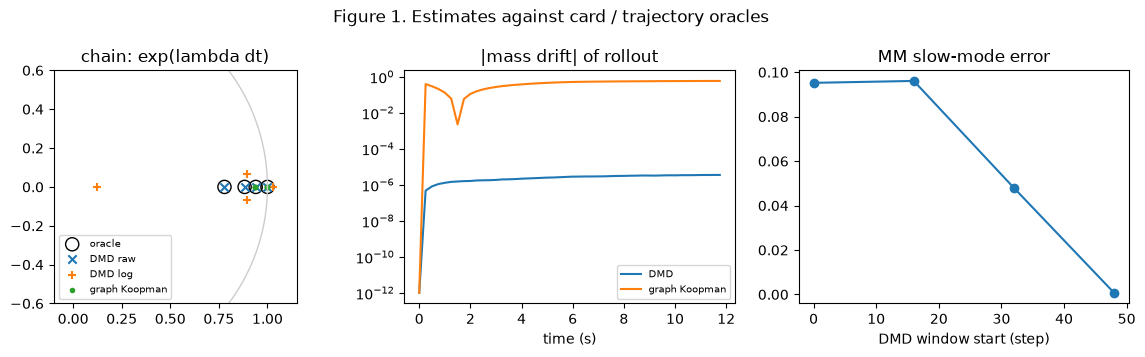

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.6))
theta = torch.linspace(0, 2 * math.pi, 200)
ax = axes[0]
ax.plot(torch.cos(theta), torch.sin(theta), color="0.8", linewidth=1)
ax.scatter(chain_oracle.real, chain_oracle.imag, s=90, facecolors="none", edgecolors="black", label="oracle")
ax.scatter(dmd_eigenvalues.real, dmd_eigenvalues.imag, marker="x", label="DMD raw")
ax.scatter(log_eigenvalues.real, log_eigenvalues.imag, marker="+", label="DMD log")
ax.scatter(neural_eigenvalues.real, neural_eigenvalues.imag, marker=".", label="graph Koopman")
ax.set_xlim(-0.1, 1.15)
ax.set_ylim(-0.6, 0.6)
ax.set_aspect("equal")
ax.set_title("chain: exp(lambda dt)")
ax.legend(fontsize=7, loc="lower left")

ax = axes[1]
ax.semilogy(chain.times, dmd_drift.clamp(min=1e-12), label="DMD")
ax.semilogy(chain.times, neural_drift.clamp(min=1e-12), label="graph Koopman")
ax.set_xlabel("time (s)")
ax.set_title("|mass drift| of rollout")
ax.legend(fontsize=7)

ax = axes[2]
ax.plot(window_starts, slow_errors, marker="o")
ax.set_xlabel("DMD window start (step)")
ax.set_title("MM slow-mode error")
fig.suptitle("Figure 1. Estimates against card / trajectory oracles")
fig.tight_layout()
plt.show()

## Interpretation / discussion

The oracle is a property of the generating mechanism, so it tests the
**identification** a model performs, not just its forecasts. On a linear
network with raw features, exact DMD is the reference estimator. If a
learned operator cannot match it there, the problem is the model or the
training, not the data.

Feature choices change what "correct" means. Log-concentration features
help when concentrations span decades (the Cantera card), but they turn a
linear chain into a nonlinear observable, and the floor flattens empty
species. Compare against the oracle in the coordinates where the oracle
holds.

For nonlinear networks the oracle spectrum is a local linearization. It
matches late-time relaxation near one equilibrium, and each trajectory's
conserved totals select a different equilibrium. The card value is the
reference at the range midpoint; per-trajectory comparisons should
recompute it with `equilibrium` and `oracle_spectrum`. Fast modes decay
within a few samples and are poorly resolved at the card's $\Delta t$.

Conservation is a separate check. Close eigenvalues do not imply a
conservative rollout, and `element_balance_violation` catches the
difference cheaply.

## Takeaways

- **When to use.** Use the card oracles to check whether a learned
  operator recovers kinetic timescales and conservation, alongside
  forecast error.
- **Coordinates.** The oracle applies to raw concentrations. The card's
  log transform is a modelling convenience, not oracle coordinates.
- **Operator choice.** Graph-level modes need a graph-coupled operator
  (`koopman="graph"`, spectrum with `edge_index`). `koopman="pernode"`
  shares one matrix across nodes.
- **Nonlinear cards.** Recompute the oracle at each trajectory's own
  equilibrium. The card value is for the range midpoint.
- **Gotchas.** `DMDBaseline` rejects hyperedge sequences; pass
  `graph_encoding="species_influence"`. The neural fit here is a short
  smoke run. Its drift shows it is not converged and says nothing about
  tuned models.

## Further reading

- Sphinx: [api](../docs/source/api.rst) (`ReactionNetworkBenchmark`,
  `koopman_graph.datasets.reaction`), [faq](../docs/source/faq.rst),
  [installation](../docs/source/installation.rst) (`[reaction]`,
  `[cantera]` extras)
- Feinberg (2019), *Foundations of Chemical Reaction Network Theory*,
  Springer ([doi:10.1007/978-3-030-03858-8](https://doi.org/10.1007/978-3-030-03858-8))
- Schmid (2010), *J. Fluid Mech.* 656, 5-28
  ([doi:10.1017/S0022112010001217](https://doi.org/10.1017/S0022112010001217);
  dynamic mode decomposition)
- Goodwin et al., Cantera 3.2.0
  ([doi:10.5281/zenodo.17620923](https://doi.org/10.5281/zenodo.17620923);
  for the `reaction_cantera_h2o2_v1` card)
- Example [07_koopman_spectrum.ipynb](07_koopman_spectrum.ipynb)
- Example [44_graphvamp_md.ipynb](44_graphvamp_md.ipynb)